# 04 - Logistic Regression Classification

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Train a binary classifier and evaluate it with multiple metrics.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

## 2. Load and split the dataset

In [2]:
dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dataset.target)

## 3. Train the model

In [3]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 4. Evaluate predictions

In [4]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1 score:  {f1_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, target_names=dataset.target_names))

Accuracy:  0.982
Precision: 0.986
Recall:    0.986
F1 score:  0.986
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



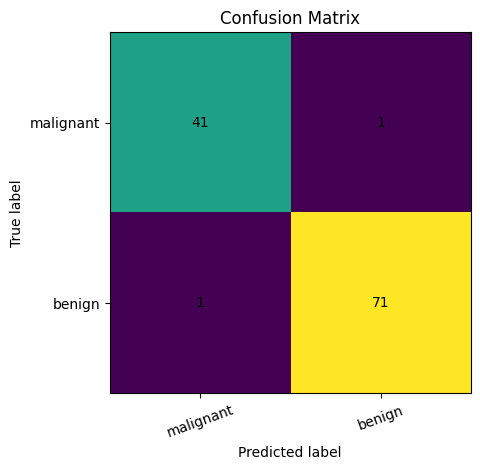

In [5]:
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], dataset.target_names, rotation=20)
plt.yticks([0, 1], dataset.target_names)
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## Exercises
1. Change `test_size`.
2. Try `class_weight="balanced"`.
3. Explain precision versus recall.